# Krok 4. Mnożnik dnia tygodnia (E1)
**Wynik z instrukcji:** o ile dany dzień tygodnia sprzedaje więcej lub mniej niż przeciętny dzień w grupie (np. Pt ×1,3, Wt ×0,8); grupy poniżej progu dostają profil sklepu. Poziom: `AsId`. Dla wariantu `baseline_2`.

**Jak liczymy.** Dla każdego asortymentu bierzemy tylko **dni czyste** (otwarte Pn-So, poza okolicami świąt i Wielkanocy, bez wierszy promocyjnych, jeśli plik ma `CzyPromocja`). Mnożnik dnia = średnia sprzedaż tego dnia tygodnia / średnia sprzedaż wszystkich dni czystych. Sobota 1,3 znaczy: sobota sprzedaje o 30 % więcej niż przeciętny dzień.

**Kiedy asortyment dostaje profil sklepu.** Małe asortymenty mają mało danych i szumny profil. Próg wyznaczamy z danych, nie arbitralnie: uczymy profil na 2023 i sprawdzamy, czy **własny** profil asortymentu lepiej odtwarza jego profil z 2024 niż **profil sklepu** z 2023. Jeśli nie, używamy profilu sklepu.

**Wynik zapisany do:** `dane/eda/wynik_04_mnoznik_dnia_tygodnia.csv`.

In [6]:
# Ustawienia wspólne: moduł eda_wspolne.py leży obok tego notebooka
import os, sys
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_wspolne as ew

ew.wejdz_do_korzenia()      # przechodzi do katalogu głównego projektu (tam, gdzie jest plik z danymi)
ew.styl()
print("Katalog projektu:", os.getcwd(), "| EDA używa danych do", ew.KONIEC_EDA.date(), "(rok testowy", ew.ROK_TEST, "pomijamy)")

Katalog projektu: /Users/mixer/python/analiza_sprzedazy_w_sklepie | EDA używa danych do 2024-12-31 (rok testowy 2025 pomijamy)


## Dane: dni × asortymenty
#### Objaśnienie
**Po co.** Mnożniki liczymy z dziennej sprzedaży asortymentu. Wiersze promocyjne (`CzyPromocja == 1`) wyrzucamy, bo promocja podbija sprzedaż niezależnie od dnia tygodnia i zafałszowałaby profil. Jeśli pliku bez tej kolumny używasz, krok się nie zatrzyma, tylko pominie ten filtr.
**Kolumna `SKLEP`.** Dodajemy sumę wszystkich asortymentów jako ostatnią kolumnę. To profil zastępczy dla małych grup.
**Jak czytać wynik.** Liczba dni czystych w każdym roku powinna być podobna (około 200-250 dni w roku). Jeśli jest ich dużo mniej, definicja dnia czystego jest zbyt ostra.

In [7]:
UZYJ_PROMO = ew.ma_kolumne("CzyPromocja")
fa = ew.wczytaj_sprzedaz(("CzyPromocja",) if UZYJ_PROMO else ())
kal = ew.kalendarz()
if UZYJ_PROMO:
    print(f"Wiersze promocyjne wyłączone z liczenia mnożników: {int((fa['CzyPromocja'] == 1).sum()):,}".replace(",", " "))
    fa = fa[fa["CzyPromocja"] != 1]
else:
    print("Uwaga: w pliku nie ma kolumny CzyPromocja, więc promocji nie wyłączamy.")
pan = ew.panel_dzienny(fa, kal, "AsId")
del fa
pan["SKLEP"] = pan.sum(axis=1)
czysty, dt, rok = kal["Czysty"].values, kal["DzienTyg"].values, kal["Rok"].values
print("Dni czyste: 2023 =", int((czysty & (rok == 2023)).sum()), "| 2024 =", int((czysty & (rok == 2024)).sum()),
      "| asortymentów:", pan.shape[1] - 1)

Wiersze promocyjne wyłączone z liczenia mnożników: 170 683
Dni czyste: 2023 = 248 | 2024 = 250 | asortymentów: 235


## Mnożniki i test: własny profil czy profil sklepu
#### Objaśnienie
**Po co.** Liczymy mnożniki Pn-So (a) z obu lat razem (wynik końcowy) oraz (b) osobno z 2023 i 2024 (do testu stabilności).
**Co robi kod.**
- `mnozniki(maska)`: dla każdej kolumny (asortymentu) średnia z dni czystych wskazanych maską i danego dnia tygodnia, podzielona przez średnią ze wszystkich tych dni.
- `blad_wlasny` = średnia |mnożnik własny z 2023 − mnożnik własny z 2024| po sześciu dniach. To miara niestabilności własnego profilu.
- `blad_sklepu` = średnia |mnożnik sklepu z 2023 − mnożnik własny z 2024|. To błąd zastępczego profilu.
- `zrodlo = wlasny`, gdy `blad_wlasny < blad_sklepu`, w przeciwnym razie `sklep`.
**Jak czytać wynik.** Duże asortymenty mają własny, stabilny profil. Małe zwykle wypadają lepiej z profilem sklepu. Zależność od wielkości widać na wykresie: dla asortymentów o małej średniej sprzedaży dziennej różnica `blad_wlasny - blad_sklepu` jest dodatnia.

In [8]:
X = pan.values
def mnozniki(maska):
    with np.errstate(all="ignore"):
        sr = X[maska].mean(axis=0)
        return np.vstack([X[maska & (dt == d)].mean(axis=0) / sr for d in range(6)])      # 6 x asortymenty

m_all = mnozniki(czysty)
m23, m24 = mnozniki(czysty & (rok == 2023)), mnozniki(czysty & (rok == 2024))
sklep = pan.shape[1] - 1
blad_wlasny = np.nanmean(np.abs(m23 - m24), axis=0)
blad_sklepu = np.nanmean(np.abs(m23[:, [sklep]] - m24), axis=0)
uzyj_wlasny = (blad_wlasny < blad_sklepu) & ~np.isnan(blad_wlasny)
uzyj_wlasny[sklep] = True                                     # sklep ma zawsze własny profil

wyn = pd.DataFrame(np.where(uzyj_wlasny[None, :], m_all, m_all[:, [sklep]]).T, index=pan.columns, columns=ew.DNI[:6])
wyn["zrodlo"] = np.where(uzyj_wlasny, "wlasny", "sklep")
wyn["srednia_dzienna"] = X[czysty].mean(axis=0)
wyn["dni_czyste_ze_sprzedaza"] = (X[czysty] > 0).sum(axis=0)
wyn["blad_wlasny"], wyn["blad_sklepu"] = blad_wlasny, blad_sklepu
print("Profil sklepu (Pn-So):", wyn.loc["SKLEP", ew.DNI[:6]].round(2).tolist())
print("Źródło profilu:", wyn["zrodlo"].value_counts().to_dict())
print(wyn.sort_values("srednia_dzienna", ascending=False).round(2).to_string())

Profil sklepu (Pn-So): [0.97, 0.98, 0.95, 0.96, 1.05, 1.1]
Źródło profilu: {'sklep': 124, 'wlasny': 112}
         Pn    Wt    Śr    Cz    Pt    So  zrodlo  srednia_dzienna  dni_czyste_ze_sprzedaza  blad_wlasny  blad_sklepu
AsId                                                                                                                 
SKLEP  0.97  0.98  0.95  0.96  1.05  1.10  wlasny          3580.85                      498         0.01         0.01
119    1.05  1.04  1.02  1.03  1.00  0.84  wlasny           201.24                      498         0.01         0.10
102    1.04  0.98  0.98  0.94  0.96  1.09  wlasny           145.09                      498         0.03         0.04
322    0.94  0.97  0.96  0.96  1.10  1.07  wlasny           143.77                      498         0.02         0.03
326    0.98  1.03  0.97  0.96  0.99  1.06  wlasny           136.99                      498         0.02         0.04
217    1.01  1.03  1.00  0.98  1.01  0.96  wlasny           129.66   

/var/folders/j5/4_q_c3nx7lv_jq3ksc9my2_m0000gn/T/ipykernel_66876/4077729188.py:10: RuntimeWarning: Mean of empty slice
  blad_wlasny = np.nanmean(np.abs(m23 - m24), axis=0)
/var/folders/j5/4_q_c3nx7lv_jq3ksc9my2_m0000gn/T/ipykernel_66876/4077729188.py:11: RuntimeWarning: Mean of empty slice
  blad_sklepu = np.nanmean(np.abs(m23[:, [sklep]] - m24), axis=0)


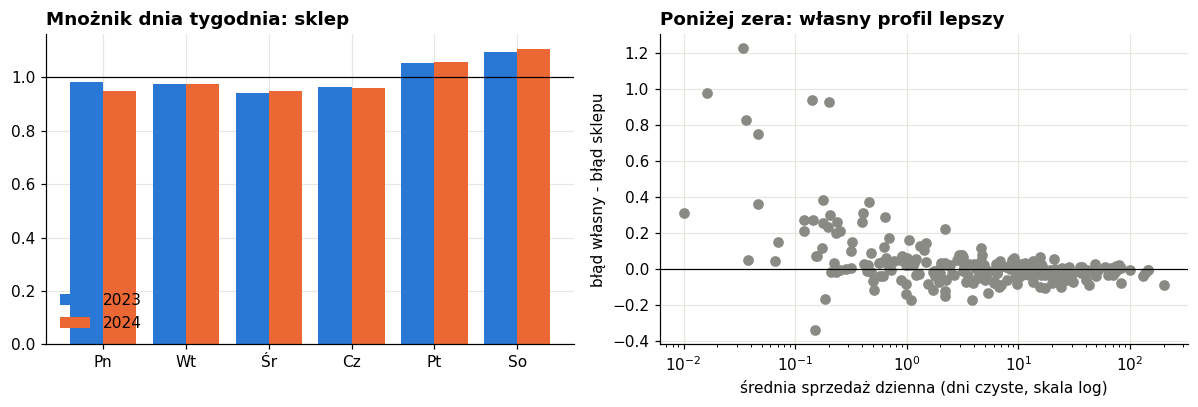

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(6)
ax[0].bar(x - 0.2, m23[:, sklep], 0.4, color=ew.NIEB, label="2023")
ax[0].bar(x + 0.2, m24[:, sklep], 0.4, color=ew.POM, label="2024")
ax[0].axhline(1, color="black", lw=0.8)
ax[0].set_xticks(x); ax[0].set_xticklabels(ew.DNI[:6]); ax[0].set_title("Mnożnik dnia tygodnia: sklep"); ax[0].legend(frameon=False)
d = wyn.drop(index="SKLEP")
ax[1].scatter(d["srednia_dzienna"], d["blad_wlasny"] - d["blad_sklepu"], color=ew.SZARY)
ax[1].axhline(0, color="black", lw=0.8); ax[1].set_xscale("log")
ax[1].set_xlabel("średnia sprzedaż dzienna (dni czyste, skala log)"); ax[1].set_ylabel("błąd własny - błąd sklepu")
ax[1].set_title("Poniżej zera: własny profil lepszy")
plt.tight_layout(); plt.show()

## Zapis
#### Objaśnienie
**Po co.** Zapisujemy końcową tabelę: dla każdego asortymentu sześć mnożników (Pn-So) i źródło profilu (`wlasny` albo `sklep`). Korzysta z niej krok 5 (mnożnik tygodnia roku) i krok 7 (promocje).
**Uwaga.** Mnożniki są względne i bezwymiarowe, więc sumują się do około 6 (średnio 1 na dzień). Niedziela handlowa nie ma tu mnożnika: dni czyste obejmują tylko Pn-So, a efekt niedzieli handlowej bada krok 6 jako wydarzenie.

In [10]:
ew.zapisz_wynik(wyn, "wynik_04_mnoznik_dnia_tygodnia.csv")

Zapisano: dane/eda/wynik_04_mnoznik_dnia_tygodnia.csv (236 wierszy)


'dane/eda/wynik_04_mnoznik_dnia_tygodnia.csv'